# LoRA SFT for the Child-Facing Chatbot (TRL + PEFT, single T4)

Re-implementation of the original RapidFire experiment without RapidFire.

- **Model**: TinyLlama-1.1B-Chat, **data**: `yxpan/children_sft_dataset` (rows 0-499 train, 500-599 eval, 600+ hold-out)
- **Configs** (same grid as the experiment report): learning rate {1e-5, 1e-4} x LoRA {r=8 on q,v ; r=32 on all linear layers}
- **Metrics**: BERTScore-F1, ROUGE-L, eval loss / mean token accuracy, training time, and age alignment
  (FKGL readability gap between the model's answer and the reference answer written for that age)
- **Final test**: base model (no SFT) vs best config on the hold-out set, overall and per age group

Everything (adapters, metrics, predictions, plots) is saved to Drive. Finished configs are skipped on re-run,
so after a runtime disconnect just run all cells again.

In [27]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U trl peft evaluate bert_score rouge_score textstat

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 0. Config

In [28]:
import os, json, time, gc, random
from collections import Counter
import numpy as np
import torch

BASE_MODEL = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DATASET = "yxpan/children_sft_dataset"
EXP_NAME = "sft_lora_v2"      # fixed name so a re-run resumes instead of starting over
SEED = 42

MAX_STEPS = 256
BATCH_SIZE = 4
EVAL_STEPS = 32
MAX_LEN = 1024
N_HOLDOUT = 600               # lower (e.g. 200) to save time on the final test

# generation settings from the original experiment; seeded so runs are repeatable
GEN_KWARGS = dict(max_new_tokens=128, do_sample=True, temperature=0.8, top_p=0.9, top_k=30,
                  repetition_penalty=1.05)
GEN_BATCH = 16

ATTN_QV = ["q_proj", "v_proj"]
ALL_LINEAR = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
CONFIGS = {
    "baseline": dict(lr=1e-5, r=8,  alpha=4,  targets=ATTN_QV),
    "A":        dict(lr=1e-4, r=8,  alpha=4,  targets=ATTN_QV),
    "B":        dict(lr=1e-5, r=32, alpha=16, targets=ALL_LINEAR),
    "C":        dict(lr=1e-4, r=32, alpha=16, targets=ALL_LINEAR),
     # follow-ups on C, one change each
    "D_lr2e-4":  dict(lr=2e-4, r=32, alpha=16, targets=ALL_LINEAR),               # higher learning rate
    "E_alpha64": dict(lr=1e-4, r=32, alpha=64, targets=ALL_LINEAR),               # LoRA scale alpha/r: 0.5 -> 2
    "F_512step": dict(lr=1e-4, r=32, alpha=16, targets=ALL_LINEAR, steps=512),    # 2x training steps
}
BEST = None                   # None = pick the SFT config with the highest eval BERT-F1

In [29]:
# Save to Drive on Colab, to $OUT_ROOT elsewhere
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = f"/content/drive/MyDrive/llm_sft_runs/{EXP_NAME}"
    TMP_DIR = "/content/tmp_sft"
except ImportError:
    OUT_DIR = os.path.join(os.environ.get("OUT_ROOT", os.path.expanduser("~/llm_sft_runs")), EXP_NAME)
    TMP_DIR = "tmp_sft"
os.makedirs(OUT_DIR, exist_ok=True)

def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=str)

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU"
import transformers, trl, peft
ENV = dict(gpu=torch.cuda.get_device_name(0), torch=torch.__version__,
           transformers=transformers.__version__, trl=trl.__version__, peft=peft.__version__)
save_json(dict(env=ENV, configs=CONFIGS, max_steps=MAX_STEPS, batch_size=BATCH_SIZE,
               gen_kwargs=GEN_KWARGS, seed=SEED), f"{OUT_DIR}/setup.json")
print(ENV); print("Outputs ->", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'gpu': 'Tesla T4', 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'trl': '1.18.1', 'peft': '0.21.3'}
Outputs -> /content/drive/MyDrive/llm_sft_runs/sft_lora_v2


## 1. Data

In [30]:
from datasets import load_dataset

ds = load_dataset(DATASET)["train"]
print(len(ds), ds.column_names)
print("age groups:", Counter(ds["age"]))

train_ds = ds.select(range(500)).shuffle(seed=SEED)
eval_ds = ds.select(range(500, 600)).shuffle(seed=SEED)
holdout_ds = ds.select(range(600, min(600 + N_HOLDOUT, len(ds))))
print(len(train_ds), len(eval_ds), len(holdout_ds))

def system_prompt(age):
    return (f"You are talking to a child aged {age}. "
            f"Generate a friendly response with age-appropriate knowledge.")

def prompt_messages(row):
    return [{"role": "system", "content": system_prompt(row["age"])},
            {"role": "user", "content": row["instruction"]}]

# prompt-completion format: loss is computed on the assistant answer only
def to_prompt_completion(row):
    return {"prompt": prompt_messages(row),
            "completion": [{"role": "assistant", "content": row["response"]}]}

train_pc = train_ds.map(to_prompt_completion, remove_columns=train_ds.column_names)
eval_pc = eval_ds.map(to_prompt_completion, remove_columns=eval_ds.column_names)
EVAL_ROWS, HOLDOUT_ROWS = list(eval_ds), list(holdout_ds)
train_pc[0]

1200 ['age', 'intent', 'instruction', 'response']
age groups: Counter({'4-6': 503, '0-3': 307, '14-18': 206, '7-9': 181, '10-13': 3})
500 100 600


{'prompt': [{'content': 'You are talking to a child aged 4-6. Generate a friendly response with age-appropriate knowledge.',
   'role': 'system'},
  {'content': 'ears', 'role': 'user'}],
 'completion': [{'content': 'Ears help you hear! They catch sounds all around you. Your ears are like little helpers that let you listen to music, your friends, and everything else.',
   'role': 'assistant'}]}

## 2. Evaluation helpers

- **BERTScore-F1 / ROUGE-L**: model answer vs reference answer
- **Age alignment**: the reference answers were written for each child's age, so their readability is the target.
  `fkgl_gap` = mean |FKGL(model answer) - FKGL(reference)| in grade levels (lower is better);
  `fkgl_within2` = share of answers within 2 grade levels of the reference (higher is better).

In [31]:
import evaluate, textstat
from transformers import AutoModelForCausalLM, AutoTokenizer

tok = AutoTokenizer.from_pretrained(BASE_MODEL)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

rouge = evaluate.load("rouge")
bertscore = evaluate.load("bertscore")

@torch.no_grad()
def generate(model, rows):
    tok.padding_side = "left"
    torch.manual_seed(SEED)
    preds = []
    for i in range(0, len(rows), GEN_BATCH):
        texts = [tok.apply_chat_template(prompt_messages(r), tokenize=False, add_generation_prompt=True)
                 for r in rows[i:i + GEN_BATCH]]
        enc = tok(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, **GEN_KWARGS, pad_token_id=tok.pad_token_id)
        preds += tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    tok.padding_side = "right"
    return [p.strip() for p in preds]

def fkgl(text):
    return textstat.flesch_kincaid_grade(text) if text.strip() else np.nan

def text_metrics(preds, rows):
    refs = [r["response"] for r in rows]
    bert = bertscore.compute(predictions=preds, references=refs, lang="en", batch_size=32)["f1"]
    gap = np.abs(np.array([fkgl(p) for p in preds]) - np.array([fkgl(t) for t in refs]))
    return dict(bert_f1=float(np.mean(bert)),
                rougeL=float(rouge.compute(predictions=preds, references=refs)["rougeL"]),
                fkgl_gap=float(np.nanmean(gap)),
                fkgl_within2=float(np.nanmean(gap <= 2)),
                empty_frac=float(np.mean([not p for p in preds])))

def per_age(preds, rows):
    out = {}
    for age in sorted(set(r["age"] for r in rows)):
        idx = [i for i, r in enumerate(rows) if r["age"] == age]
        out[age] = dict(n=len(idx), **text_metrics([preds[i] for i in idx], [rows[i] for i in idx]))
    return out

def save_preds(preds, rows, path):
    with open(path, "w") as f:
        for p, r in zip(preds, rows):
            f.write(json.dumps(dict(age=r["age"], instruction=r["instruction"],
                                    reference=r["response"], prediction=p)) + "\n")

def load_base():
    return AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda").eval()

def free(*objs):
    for o in objs:
        del o
    gc.collect(); torch.cuda.empty_cache()

## 3. Base model (no SFT) on the eval set

In [32]:
base_path = f"{OUT_DIR}/base/metrics.json"
if os.path.exists(base_path):
    print("skip, already done"); BASE_METRICS = json.load(open(base_path))
else:
    os.makedirs(f"{OUT_DIR}/base", exist_ok=True)
    model = load_base()
    preds = generate(model, EVAL_ROWS)
    BASE_METRICS = dict(config="base (no SFT)", **text_metrics(preds, EVAL_ROWS))
    save_preds(preds, EVAL_ROWS, f"{OUT_DIR}/base/eval_preds.jsonl")
    save_json(BASE_METRICS, base_path)
    free(model)
print(BASE_METRICS)

skip, already done
{'config': 'base (no SFT)', 'bert_f1': 0.8439911496639252, 'rougeL': 0.12318092970119882, 'fkgl_gap': 3.9111789981842735, 'fkgl_within2': 0.37, 'empty_frac': 0.0}


## 4. Train the four LoRA configs

In [33]:
!pip uninstall -y torchao

In [34]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

def train_one(name, cfg):
    run_dir = f"{OUT_DIR}/{name}"
    if os.path.exists(f"{run_dir}/metrics.json"):
        print(f"[{name}] skip, already done")
        return json.load(open(f"{run_dir}/metrics.json"))
    os.makedirs(run_dir, exist_ok=True)

    model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda")
    peft_cfg = LoraConfig(r=cfg["r"], lora_alpha=cfg["alpha"], lora_dropout=0.1,
                          target_modules=cfg["targets"], bias="none", task_type="CAUSAL_LM")
    args = SFTConfig(output_dir=f"{TMP_DIR}/{name}", learning_rate=cfg["lr"], lr_scheduler_type="linear",
                     per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
                     max_steps=cfg.get("steps", MAX_STEPS), logging_steps=8, eval_strategy="steps", eval_steps=EVAL_STEPS,
                     save_strategy="no", fp16=True, max_length=MAX_LEN, seed=SEED, report_to="none")
    trainer = SFTTrainer(model=model, args=args, train_dataset=train_pc, eval_dataset=eval_pc,
                         processing_class=tok, peft_config=peft_cfg)
    n_trainable = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)

    t0 = time.time(); trainer.train(); train_min = (time.time() - t0) / 60
    ev = trainer.evaluate()
    trainer.model.save_pretrained(f"{run_dir}/adapter")
    tok.save_pretrained(f"{run_dir}/adapter")
    save_json(trainer.state.log_history, f"{run_dir}/log_history.json")

    m = trainer.model.eval(); m.config.use_cache = True
    preds = generate(m, EVAL_ROWS)
    save_preds(preds, EVAL_ROWS, f"{run_dir}/eval_preds.jsonl")
    metrics = dict(config=name, lr=cfg["lr"], r=cfg["r"], alpha=cfg["alpha"],
                   targets="all linear" if cfg["targets"] == ALL_LINEAR else ",".join(cfg["targets"]),
                   trainable_params=n_trainable, train_min=round(train_min, 2),
                   eval_loss=ev.get("eval_loss"), eval_token_acc=ev.get("eval_mean_token_accuracy"),
                   **text_metrics(preds, EVAL_ROWS))
    save_json(metrics, f"{run_dir}/metrics.json")
    free(trainer, model, m)
    print(f"[{name}]", metrics)
    return metrics

RESULTS = {name: train_one(name, cfg) for name, cfg in CONFIGS.items()}

[baseline] skip, already done
[A] skip, already done
[B] skip, already done
[C] skip, already done
[D_lr2e-4] skip, already done
[E_alpha64] skip, already done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'loss': '1.993', 'grad_norm': '0.6136', 'learning_rate': '9.863e-05', 'entropy': '1.619', 'mean_token_accuracy': '0.5448', 'num_tokens': '3528', 'epoch': '0.064'}
{'loss': '1.607', 'grad_norm': '1.203', 'learning_rate': '9.707e-05', 'entropy': '1.511', 'mean_token_accuracy': '0.6009', 'num_tokens': '6587', 'epoch': '0.128'}
{'loss': '1.524', 'grad_norm': '0.5679', 'learning_rate': '9.551e-05', 'entropy': '1.609', 'mean_token_accuracy': '0.6009', 'num_tokens': '9829', 'epoch': '0.192'}
{'loss': '1.583', 'grad_norm': '0.7064', 'learning_rate': '9.395e-05', 'entropy': '1.64', 'mean_token_accuracy': '0.5797', 'num_tokens': '1.386e+04', 'epoch': '0.256'}
{'eval_loss': '1.463', 'eval_runtime': '2.988', 'eval_samples_per_second': '33.46', 'eval_steps_per_second': '8.366', 'eval_entropy': '1.562', 'eval_mean_token_accuracy': '0.6166', 'eval_num_tokens': '1.386e+04', 'epoch': '0.256'}
{'loss': '1.469', 'grad_norm': '0.74', 'learning_rate': '9.238e-05', 'entropy': '1.592', 'mean_token_accuracy'

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[F_512step] {'config': 'F_512step', 'lr': 0.0001, 'r': 32, 'alpha': 16, 'targets': 'all linear', 'trainable_params': 25231360, 'train_min': 4.76, 'eval_loss': 1.4090325832366943, 'eval_token_acc': 0.6415987277030945, 'bert_f1': 0.8860918712615967, 'rougeL': 0.23795944979407288, 'fkgl_gap': 1.900212142082112, 'fkgl_within2': 0.61, 'empty_frac': 0.0}


## 5. Compare configs

,lr,r,targets,trainable_params,train_min,eval_loss,eval_token_acc,bert_f1,rougeL,fkgl_gap,fkgl_within2,empty_frac
config,,,,,,,,,,,,
base (no SFT),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8440,0.1232,3.9112,0.37,0.0
baseline,0.0000,8.0,"q_proj,v_proj",1126400.0,3.80,2.0731,0.5273,0.8496,0.1380,3.5396,0.36,0.0
A,0.0001,8.0,"q_proj,v_proj",1126400.0,1.80,1.4715,0.6129,0.8752,0.1852,2.4596,0.49,0.0
B,0.0000,32.0,all linear,25231360.0,2.59,1.5030,0.6081,0.8756,0.1916,2.5691,0.44,0.0
C,0.0001,32.0,all linear,25231360.0,2.63,1.3304,0.6433,0.8838,0.2427,1.9956,0.62,0.0
D_lr2e-4,0.0002,32.0,all linear,25231360.0,4.32,1.3168,0.6495,0.8834,0.2280,1.9163,0.64,0.0
E_alpha64,0.0001,32.0,all linear,25231360.0,2.39,1.3207,0.6503,0.8864,0.2534,1.8448,0.68,0.0
F_512step,0.0001,32.0,all linear,25231360.0,4.76,1.4090,0.6416,0.8861,0.2380,1.9002,0.61,0.0


best config: E_alpha64


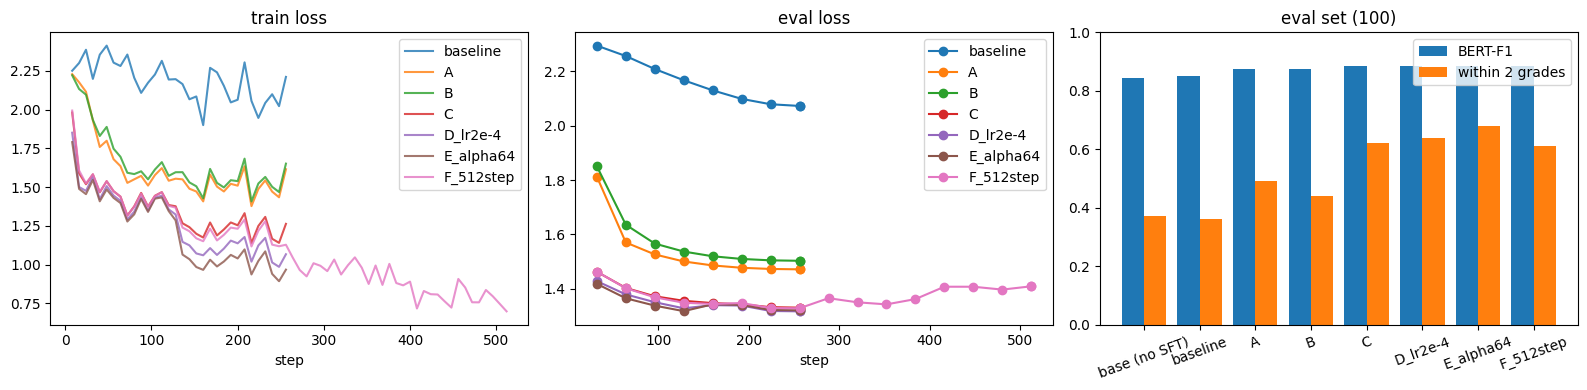

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

table = pd.DataFrame([BASE_METRICS] + list(RESULTS.values())).set_index("config")
cols = ["lr", "r", "targets", "trainable_params", "train_min", "eval_loss", "eval_token_acc",
        "bert_f1", "rougeL", "fkgl_gap", "fkgl_within2", "empty_frac"]
table = table[[c for c in cols if c in table.columns]]
display(table.round(4))
table.to_csv(f"{OUT_DIR}/config_comparison.csv")

if BEST is None:
    BEST = max(RESULTS, key=lambda k: RESULTS[k]["bert_f1"])
print("best config:", BEST)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name in CONFIGS:
    hist = json.load(open(f"{OUT_DIR}/{name}/log_history.json"))
    tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
    axes[0].plot(*zip(*tr), label=name, alpha=0.8)
    axes[1].plot(*zip(*ev), "o-", label=name)
axes[0].set_title("train loss"); axes[1].set_title("eval loss")
for ax in axes[:2]:
    ax.set_xlabel("step"); ax.legend()
names = list(table.index)
x = np.arange(len(names))
axes[2].bar(x - 0.2, table["bert_f1"], 0.4, label="BERT-F1")
axes[2].bar(x + 0.2, table["fkgl_within2"], 0.4, label="within 2 grades")
axes[2].set_xticks(x, names, rotation=20); axes[2].set_ylim(0, 1); axes[2].legend()
axes[2].set_title("eval set (100)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/config_comparison.png", dpi=150); plt.show()

## 6. Final test: base vs best config on the hold-out set

The hold-out rows were never used for training or for choosing the config.

In [36]:
from peft import PeftModel

final_path = f"{OUT_DIR}/holdout_{BEST}.json"
if os.path.exists(final_path):
    print("skip, already done"); FINAL = json.load(open(final_path))
else:
    FINAL = {}
    model = load_base()
    preds = generate(model, HOLDOUT_ROWS)
    save_preds(preds, HOLDOUT_ROWS, f"{OUT_DIR}/base/holdout_preds.jsonl")
    FINAL["base"] = dict(overall=text_metrics(preds, HOLDOUT_ROWS), per_age=per_age(preds, HOLDOUT_ROWS))
    save_json(FINAL, final_path + ".partial")

    model = PeftModel.from_pretrained(model, f"{OUT_DIR}/{BEST}/adapter").eval()
    preds = generate(model, HOLDOUT_ROWS)
    save_preds(preds, HOLDOUT_ROWS, f"{OUT_DIR}/{BEST}/holdout_preds.jsonl")
    FINAL[BEST] = dict(overall=text_metrics(preds, HOLDOUT_ROWS), per_age=per_age(preds, HOLDOUT_ROWS))
    save_json(FINAL, final_path)
    free(model)

b, s = FINAL["base"]["overall"], FINAL[BEST]["overall"]
summary = pd.DataFrame({"base": b, BEST: s}).T
summary.loc["relative change"] = [(s[k] - b[k]) / b[k] if b[k] else np.nan for k in summary.columns]
display(summary.round(4))
summary.to_csv(f"{OUT_DIR}/holdout_summary.csv")

rows = []
for age in FINAL["base"]["per_age"]:
    rb, rs = FINAL["base"]["per_age"][age], FINAL[BEST]["per_age"][age]
    rows.append(dict(age=age, n=rb["n"], bert_f1_base=rb["bert_f1"], bert_f1_sft=rs["bert_f1"],
                     fkgl_gap_base=rb["fkgl_gap"], fkgl_gap_sft=rs["fkgl_gap"],
                     within2_base=rb["fkgl_within2"], within2_sft=rs["fkgl_within2"]))
by_age = pd.DataFrame(rows).set_index("age")
display(by_age.round(3))
by_age.to_csv(f"{OUT_DIR}/holdout_by_age.csv")

skip, already done


,bert_f1,rougeL,fkgl_gap,fkgl_within2,empty_frac
base,0.8479,0.1389,3.4581,0.3500,0.0
E_alpha64,0.8831,0.2253,2.1561,0.5933,0.0
relative change,0.0415,0.6215,-0.3765,0.6952,NaN


,n,bert_f1_base,bert_f1_sft,fkgl_gap_base,fkgl_gap_sft,within2_base,within2_sft
age,,,,,,,
0-3,192,0.841,0.886,3.426,2.105,0.359,0.599
10-13,3,0.863,0.892,1.868,2.394,0.667,0.333
14-18,112,0.842,0.868,2.931,3.511,0.339,0.384
4-6,222,0.855,0.889,3.926,1.624,0.315,0.685
7-9,71,0.853,0.878,2.982,1.811,0.437,0.634


## 7. Adapter for the serving benchmark

In [37]:
ADAPTER_PATH = f"{OUT_DIR}/{BEST}/adapter"
print("Set ADAPTER_PATH in vllm_serving_benchmark.ipynb to:\n ", ADAPTER_PATH)
# Optional: push to the Hugging Face Hub so other notebooks / machines can load it by name
# from huggingface_hub import login; login()
# PeftModel.from_pretrained(load_base(), ADAPTER_PATH).push_to_hub("yxpan/tinyllama-child-sft-lora")

Set ADAPTER_PATH in vllm_serving_benchmark.ipynb to:
  /content/drive/MyDrive/llm_sft_runs/sft_lora_v2/E_alpha64/adapter
